# Перевод с русского на английский (Transformer)

В Kaggle включи GPU и Internet, затем нажми Run All. Корпус скачивается при первом запуске. Результаты сохраняются в `/kaggle/working/translation_project/transformer/`. [Данные ManyThings](https://www.manythings.org/anki/)


In [1]:
import io
import json
import math
import random
import re
import subprocess
import sys
import time
import unicodedata
import urllib.request
import zipfile
from collections import Counter
from itertools import zip_longest
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import torch
from IPython.display import display
from torch import nn
from torch.nn.utils.rnn import pad_sequence

try:
    from sacrebleu.metrics import BLEU, CHRF
except ModuleNotFoundError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "sacrebleu==2.5.1"])
    from sacrebleu.metrics import BLEU, CHRF

SEED = 42
VOCAB_SIZE = 5000
DIM = 128
HEADS = 4
FF_DIM = 256
BATCH_SIZE = 64
TOKEN_BUDGET = 2048
EPOCHS = 20
MAX_NEW_TOKENS = 128
DATA_PATH = None  # Локальный rus.txt или rus-eng.zip

DEVICE = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
OUT = Path("/kaggle/working/translation_project/transformer")
OUT.mkdir(parents=True, exist_ok=True)
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True
DEVICE_NAME = torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "CPU"
print("Устройство", DEVICE_NAME)


Устройство Tesla T4


## Данные

Все варианты перевода одной русской фразы попадают в одну часть выборки.


In [2]:
URLS = [
    "https://www.manythings.org/anki/rus-eng.zip",
    "https://mail.manythings.org/anki/rus-eng.zip",
]
HEADERS = {
    "User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 "
                  "(KHTML, like Gecko) Chrome/131.0.0.0 Safari/537.36",
    "Accept": "application/zip, application/octet-stream;q=0.9, */*;q=0.8",
    "Accept-Language": "en-US,en;q=0.9",
    "Referer": "https://www.manythings.org/anki/",
}

def unzip(content):
    with zipfile.ZipFile(io.BytesIO(content)) as archive:
        return archive.read("rus.txt").decode("utf-8-sig")

def load_corpus():
    if DATA_PATH:
        path = Path(DATA_PATH)
        return unzip(path.read_bytes()) if path.suffix == ".zip" else path.read_text(encoding="utf-8-sig")
    path = OUT / "rus-eng.zip"
    if path.exists():
        try:
            return unzip(path.read_bytes())
        except (zipfile.BadZipFile, KeyError, UnicodeError):
            pass
    errors = []
    for url in URLS:
        try:
            request = urllib.request.Request(url, headers=HEADERS)
            with urllib.request.urlopen(request, timeout=45) as response:
                content = response.read()
            text = unzip(content)
        except (OSError, zipfile.BadZipFile, KeyError, UnicodeError) as error:
            errors.append(f"{url}: {error}")
            continue
        path.write_bytes(content)
        return text
    raise RuntimeError("Не удалось скачать корпус.\n" + "\n".join(errors))


In [3]:
APOSTROPHES = str.maketrans("\u2019\u2018\u02bc", "'''")
TOKEN_PATTERN = re.compile(r"[^\W\d_]+(?:'[^\W\d_]+)*|\d+(?:[.,]\d+)*|[^\w\s]|_")

def tokenize(text):
    text = unicodedata.normalize("NFC", text).lower().translate(APOSTROPHES)
    return TOKEN_PATTERN.findall(text)

def detokenize(tokens):
    text = re.sub(r"\s+([.,!?;:%)\]}])", r"\1", " ".join(tokens))
    return re.sub(r"([(\[{])\s+", r"\1", text).strip()

text = load_corpus()
data = pd.DataFrame(
    [line.split("\t", 2) for line in text.splitlines() if line.count("\t") >= 2],
    columns=["en", "ru", "attribution"],
)
del text
for language in ["ru", "en"]:
    data[language] = data[language].map(lambda text: " ".join(tokenize(text)))
data = data[(data.ru != "") & (data.en != "")].drop_duplicates(["ru", "en"])

sources = sorted(data.ru.unique())
assert len(sources) >= 10, "Недостаточно корректных русских фраз."
random.Random(SEED + 1).shuffle(sources)
train_end = int(0.8 * len(sources))
val_end = train_end + int(0.1 * len(sources))
data["order"] = data.ru.map({source: i for i, source in enumerate(sources)})
data["split"] = "test"
data.loc[data.order < val_end, "split"] = "validation"
data.loc[data.order < train_end, "split"] = "train"
data = data.sort_values(["order", "en"]).drop(columns="order").reset_index(drop=True)

train = data[data.split == "train"]
val = data[data.split == "validation"]
test = data[data.split == "test"].groupby("ru", sort=False).agg(
    references=("en", list), attribution=("attribution", list)
).reset_index()
assert set(train.ru).isdisjoint(val.ru)
assert set(train.ru).isdisjoint(test.ru)
assert set(val.ru).isdisjoint(test.ru)
display(data.groupby("split").agg(pairs=("ru", "size"), sources=("ru", "nunique")))


,pairs,sources
split,,
test,53380,46334
train,426914,370668
validation,53361,46333


## Словари и батчи

Словари строим по обучающей выборке. Длинные фразы собираем в меньшие батчи.


In [4]:
SPECIAL = ["<pad>", "<unk>", "<bos>", "<eos>"]
PAD, UNK, BOS, EOS = range(4)

def build_vocab(texts):
    counts = Counter(token for text in texts for token in text.split())
    words = sorted(counts, key=lambda word: (-counts[word], word))
    return {word: i for i, word in enumerate(SPECIAL + words[:VOCAB_SIZE - 4])}

ru_vocab = build_vocab(train.ru)
en_vocab = build_vocab(train.en)
en_words = list(en_vocab)

def encode(text, vocab):
    ids = [BOS] + [vocab.get(token, UNK) for token in tokenize(text)] + [EOS]
    return torch.tensor(ids, dtype=torch.long)

def encode_pairs(sources, targets):
    return [
        (encode(ru, ru_vocab), encode(en, en_vocab))
        for ru, en in zip(sources, targets)
    ]

train_samples = encode_pairs(train.ru, train.en)
val_samples = encode_pairs(val.ru, val.en)
test_samples = encode_pairs(test.ru, (refs[0] for refs in test.references))


In [5]:
def batch_indices(samples, shuffle=False, epoch=0):
    indices = list(range(len(samples)))
    if shuffle:
        random.Random(SEED + epoch).shuffle(indices)
    batch, longest = [], 0
    for index in indices:
        length = max(len(part) for part in samples[index])
        longest = max(longest, length)
        if batch and (len(batch) == BATCH_SIZE or (len(batch) + 1) * longest > TOKEN_BUDGET):
            yield batch
            batch, longest = [], length
        batch.append(index)
    if batch:
        yield batch

def batches(samples, shuffle=False, epoch=0):
    for indices in batch_indices(samples, shuffle, epoch):
        sources, targets = zip(*(samples[i] for i in indices))
        yield (
            pad_sequence(sources, batch_first=True, padding_value=PAD).to(DEVICE),
            pad_sequence(targets, batch_first=True, padding_value=PAD).to(DEVICE),
        )


## Модель

К embeddings добавляем позиционное кодирование. Маски закрывают PAD и будущие токены в декодере.


In [6]:
class Seq2SeqTransformer(nn.Module):
    def __init__(self):
        super().__init__()
        self.ru_embedding = nn.Embedding(len(ru_vocab), DIM, padding_idx=PAD)
        self.en_embedding = nn.Embedding(len(en_vocab), DIM, padding_idx=PAD)
        self.transformer = nn.Transformer(
            d_model=DIM, nhead=HEADS, num_encoder_layers=1, num_decoder_layers=1,
            dim_feedforward=FF_DIM, dropout=0.1, batch_first=True,
        )
        self.output = nn.Linear(DIM, len(en_vocab))
        frequencies = torch.exp(-math.log(10000.0) * torch.arange(0, DIM, 2) / DIM)
        self.register_buffer("frequencies", frequencies, persistent=False)

    def add_positions(self, embedded):
        positions = torch.arange(embedded.size(1), device=embedded.device)
        angles = positions[:, None] * self.frequencies
        encoding = torch.stack((angles.sin(), angles.cos()), dim=-1).flatten(1)
        return embedded + encoding

    def encode(self, source, source_padding):
        return self.transformer.encoder(
            self.add_positions(self.ru_embedding(source)),
            src_key_padding_mask=source_padding,
        )

    def decode(self, target_input, memory, source_padding):
        length = target_input.size(1)
        future = torch.ones(length, length, dtype=torch.bool, device=target_input.device).triu(1)
        return self.transformer.decoder(
            self.add_positions(self.en_embedding(target_input)),
            memory,
            tgt_mask=future,
            tgt_key_padding_mask=target_input.eq(PAD),
            memory_key_padding_mask=source_padding,
        )

    def forward(self, source, target_input):
        source_padding = source.eq(PAD)
        memory = self.encode(source, source_padding)
        return self.output(self.decode(target_input, memory, source_padding))

torch.manual_seed(SEED)
model = Seq2SeqTransformer().to(DEVICE)


## Обучение

Декодер учится предсказывать следующий токен по предыдущим токенам эталона. Для теста берём веса с минимальным loss на валидации.


In [7]:
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
criterion = nn.CrossEntropyLoss(ignore_index=PAD, reduction="sum")

def synchronize():
    if DEVICE.type == "cuda":
        torch.cuda.synchronize(DEVICE)

def run_epoch(samples, training=False, epoch=0):
    model.train(training)
    total_loss, tokens = 0.0, 0
    with torch.set_grad_enabled(training):
        for source, target in batches(samples, shuffle=training, epoch=epoch):
            if training:
                optimizer.zero_grad(set_to_none=True)
            logits = model(source, target[:, :-1])
            labels = target[:, 1:]
            loss = criterion(logits.reshape(-1, len(en_vocab)), labels.reshape(-1))
            count = labels.ne(PAD).sum()
            assert torch.isfinite(loss).item(), "Получен неконечный loss."
            if training:
                (loss / count).backward()
                nn.utils.clip_grad_norm_(model.parameters(), 1.0, error_if_nonfinite=True)
                optimizer.step()
            total_loss += loss.item()
            tokens += count.item()
    return total_loss / tokens


In [8]:
best_loss = float("inf")
bad_epochs = 0
history = []
synchronize()
training_start = time.perf_counter()

for epoch in range(EPOCHS):
    start = time.perf_counter()
    train_loss = run_epoch(train_samples, training=True, epoch=epoch)
    val_loss = run_epoch(val_samples)
    if val_loss < best_loss:
        best_loss = val_loss
        bad_epochs = 0
        torch.save({
            "model": model.state_dict(), "ru_vocab": ru_vocab, "en_vocab": en_vocab,
            "dim": DIM, "heads": HEADS, "ff_dim": FF_DIM, "epoch": epoch + 1,
        }, OUT / "transformer.pt")
    else:
        bad_epochs += 1
    synchronize()
    seconds = time.perf_counter() - start
    history.append([epoch + 1, train_loss, val_loss, seconds])
    print(f"Эпоха {epoch + 1}, train {train_loss:.3f}, val {val_loss:.3f}, {seconds:.1f} с")
    if epoch == 0:
        print(f"До лимита эпох около {seconds * (EPOCHS - 1) / 60:.1f} мин.")
    if bad_epochs == 3:
        break

training_seconds = time.perf_counter() - training_start
checkpoint = torch.load(OUT / "transformer.pt", map_location=DEVICE, weights_only=True)
model.load_state_dict(checkpoint["model"])
history = pd.DataFrame(history, columns=["epoch", "train_loss", "val_loss", "seconds"])
history.to_csv(OUT / "history.csv", index=False)
print(f"Лучшая эпоха {checkpoint['epoch']}. Обучение заняло {training_seconds / 60:.2f} мин.")


/usr/local/lib/python3.13/dist-packages/torch/nn/modules/transformer.py:531: UserWarning: The PyTorch API of nested tensors is in prototype stage and will change in the near future. We recommend specifying layout=torch.jagged when constructing a nested tensor, as this layout receives active development, has better operator coverage, and works with torch.compile. (Triggered internally at /pytorch/aten/src/ATen/NestedTensorImpl.cpp:178.)
  output = torch._nested_tensor_from_mask(


Эпоха 1, train 2.095, val 1.417, 77.9 с
До лимита эпох около 24.7 мин.
Эпоха 2, train 1.392, val 1.210, 75.2 с
Эпоха 3, train 1.228, val 1.117, 74.5 с
Эпоха 4, train 1.137, val 1.063, 73.5 с
Эпоха 5, train 1.077, val 1.029, 73.8 с
Эпоха 6, train 1.030, val 0.998, 74.9 с
Эпоха 7, train 0.994, val 0.977, 74.5 с
Эпоха 8, train 0.964, val 0.961, 74.9 с
Эпоха 9, train 0.939, val 0.942, 74.5 с
Эпоха 10, train 0.918, val 0.935, 73.9 с
Эпоха 11, train 0.898, val 0.925, 74.4 с
Эпоха 12, train 0.881, val 0.917, 74.7 с
Эпоха 13, train 0.866, val 0.903, 74.8 с
Эпоха 14, train 0.854, val 0.896, 74.5 с
Эпоха 15, train 0.841, val 0.894, 74.4 с
Эпоха 16, train 0.830, val 0.886, 74.1 с
Эпоха 17, train 0.820, val 0.884, 74.1 с
Эпоха 18, train 0.811, val 0.878, 73.7 с
Эпоха 19, train 0.802, val 0.875, 74.1 с
Эпоха 20, train 0.793, val 0.869, 73.9 с
Лучшая эпоха 20. Обучение заняло 24.84 мин.


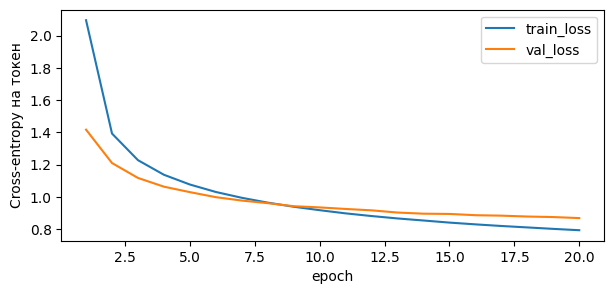

In [9]:
history.plot(x="epoch", y=["train_loss", "val_loss"], figsize=(7, 3))
plt.ylabel("Cross-entropy на токен")
plt.show()


## Генерация

На каждом шаге выбираем самый вероятный токен. Генерация заканчивается по EOS или после 128 токенов.


In [10]:
def decode(ids):
    if EOS in ids:
        ids = ids[:ids.index(EOS)]
    return detokenize([en_words[i] for i in ids if i not in (PAD, BOS)])

@torch.inference_mode()
def generate(source):
    model.eval()
    source_padding = source.eq(PAD)
    memory = model.encode(source, source_padding)
    prefix = torch.full((source.size(0), 1), BOS, device=DEVICE, dtype=torch.long)
    finished = torch.zeros(source.size(0), dtype=torch.bool, device=DEVICE)
    for _ in range(MAX_NEW_TOKENS):
        states = model.decode(prefix, memory, source_padding)
        scores = model.output(states[:, -1])
        scores[:, [PAD, BOS]] = -torch.inf
        next_token = scores.argmax(dim=-1)
        next_token[finished] = PAD
        prefix = torch.cat((prefix, next_token[:, None]), dim=1)
        finished |= next_token.eq(EOS)
        if finished.all().item():
            break
    return [decode(ids) for ids in prefix[:, 1:].cpu().tolist()]


## Тест

Для каждой русской фразы генерируем один перевод. BLEU и chrF учитывают все её эталоны.


In [11]:
synchronize()
start = time.perf_counter()
predictions = []
for source, _ in batches(test_samples):
    predictions.extend(generate(source))
synchronize()
generation_seconds = time.perf_counter() - start
assert len(predictions) == len(test)

references = [[detokenize(text.split()) for text in refs] for refs in test.references]
reference_streams = list(zip_longest(*references, fillvalue=None))
bleu = BLEU(tokenize="13a")
chrf = CHRF(char_order=6, word_order=0, beta=2)
bleu_score = bleu.corpus_score(predictions, reference_streams).score
chrf_score = chrf.corpus_score(predictions, reference_streams).score

translations = test.assign(
    ru=test.ru.map(lambda text: detokenize(text.split())),
    prediction=predictions,
    reference=[refs[0] for refs in references],
)
display(translations[["ru", "reference", "prediction"]].sample(min(10, len(test)), random_state=SEED))
results = {
    "BLEU": bleu_score, "chrF": chrf_score, "best_epoch": checkpoint["epoch"],
    "train_pairs": len(train), "test_sources": len(test),
    "parameters": sum(p.numel() for p in model.parameters()),
    "training_seconds": training_seconds, "generation_seconds": generation_seconds,
    "seed": SEED, "dim": DIM, "ru_vocab_size": len(ru_vocab), "en_vocab_size": len(en_vocab), "max_new_tokens": MAX_NEW_TOKENS,
    "batch_size": BATCH_SIZE, "token_budget": TOKEN_BUDGET, "learning_rate": 0.001,
    "epochs_completed": len(history), "device": DEVICE_NAME,
    "evaluation": "unique_ru/all_references",
    "bleu_signature": str(bleu.get_signature()), "chrf_signature": str(chrf.get_signature()),
}
print(f"BLEU {bleu_score:.2f}, chrF {chrf_score:.2f}")
print(f"Параметров {results['parameters']:,}. Перевод теста занял {generation_seconds:.2f} с.")

(OUT / "results.json").write_text(json.dumps(results, ensure_ascii=False, indent=2), encoding="utf-8")
for column in ["references", "attribution"]:
    translations[column] = translations[column].map(json.dumps)
translations.to_csv(OUT / "predictions.csv", index=False)


,ru,reference,prediction
23014,"скажи, что это неправда.",say it isn't true.,say that isn't true.
35067,почему вы дома?,why are you at home?,why are you home?
8023,"я рад, что я не том.",i'm glad i'm not tom.,i'm glad that i'm not tom.
776,"том не будет делать так, как вы предложили.",tom won't do as you suggested.,tom won't do as you suggested.
36270,не говорите моей жене.,don't tell my wife.,don't tell my wife.
18575,я была бы благодарна.,i'd be grateful.,i'd be <unk>.
6994,ты каждый день занимаешься французским?,do you study french every day?,do you study french every day?
21022,почему бы тебе не нанять частного детектива?,why don't you hire a private detective?,why don't you hire a private detective?
36459,спасибо за твой подарок.,thank you for your gift.,thanks for your present.
12098,эта работа довольно хорошо оплачивается.,this job pays pretty well.,this job is quite good.


BLEU 47.82, chrF 62.44
Параметров 2,256,776. Перевод теста занял 24.28 с.


## Свои фразы


In [12]:
def translate(text):
    source = encode(text, ru_vocab)
    if len(source) == 2:
        raise ValueError("Введите непустую фразу.")
    return generate(source.unsqueeze(0).to(DEVICE))[0]

for text in ["Я хочу пить.", "Где мой телефон?", "Она читает книгу."]:
    print(text, translate(text), sep="\n", end="\n\n")


Я хочу пить.
i want to drink.

Где мой телефон?
where's my phone?

Она читает книгу.
she reads the book.

